# Projekt 2 – predykcja ceny za m² mieszkań (rynek wtórny, Poznań)

Baseline na cechach strukturalnych, potem dokładamy informacje z tekstu ogłoszenia:
TF-IDF, embeddingi (Sentence-BERT, OpenAI) i cechy wyciągnięte przez LLM.
Wszystkie modele oceniamy na tym samym zbiorze testowym.

Kroki z OpenAI API zostały uruchomione raz, a odpowiedzi są zapisane w `cache/` i `results/`.
Notebook tylko je wczytuje.

In [1]:
import hashlib
import html
import json
import re

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

## 1. Wczytanie danych

In [2]:
raw = pd.read_csv("data/real_estate_ads.csv")
print("liczba ogłoszeń:", len(raw))
print(raw["market"].value_counts())

df = raw[raw["market"] == "secondary"].reset_index(drop=True)
print("rynek wtórny:", len(df))

liczba ogłoszeń: 13745
market
primary      7791
secondary    5954
Name: count, dtype: int64
rynek wtórny: 5954


## 2. Cechy z kolumny `params`

`params` to jeden tekst w formacie `klucz<=>wartość<br>klucz<=>wartość...`. Rozbijamy go na osobne kolumny.

In [3]:
def parse_params(s):
    pairs = [part.split("<=>", 1) for part in s.split("<br>") if "<=>" in part]
    return dict(pairs)


params = pd.DataFrame([parse_params(p) for p in df["params"]]).replace("", np.nan)
params.head()

,price,price[currency],m,rooms_num,market,building_type,floor_no,building_floors_num,building_material,windows_type,...,rent,rent[currency],building_ownership,free_from,media_types,security_types,equipment_types,extras_types,price_per_m,remote_services
0,289000,PLN,48,3,secondary,block,floor_1,4,NaN,plastic,...,NaN,PLN,co_operative_ownership_with_a_land_and_mortgag...,NaN,cable-television<->internet<->phone,NaN,NaN,balcony<->separate_kitchen,6020.83,NaN
1,379000,PLN,61,3,secondary,block,ground_floor,4,NaN,wooden,...,550,PLN,co_operative_ownership_with_a_land_and_mortgag...,NaN,cable-television<->internet,NaN,NaN,balcony,6213.11,NaN
2,339000,PLN,63,3,secondary,block,floor_3,4,concrete_plate,NaN,...,NaN,PLN,co_operative_ownership,NaN,NaN,entryphone,NaN,balcony<->basement,5380.95,NaN
3,330000,PLN,59.2,3,secondary,block,floor_1,4,concrete_plate,wooden,...,NaN,PLN,co_operative_ownership,NaN,NaN,entryphone,NaN,balcony<->basement,5574.32,NaN
4,259000,PLN,38,2,secondary,block,floor_1,10,concrete_plate,plastic,...,NaN,PLN,co_operative_ownership_with_a_land_and_mortgag...,NaN,cable-television<->internet<->phone,entryphone,fridge<->furniture<->stove<->washing_machine,basement,6815.79,NaN


In [4]:
data = df[["id", "price", "m", "price_per_m", "map_lat", "map_lon", "district_lat", "district_lon"]].copy()
data["created_at_first"] = pd.to_datetime(df["created_at_first"])
data["no_rooms"] = pd.to_numeric(df["no_rooms"].replace("more", "8"))

floor_map = {"ground_floor": 0, "floor_higher_10": 11}
for i in range(1, 11):
    floor_map[f"floor_{i}"] = i
data["floor"] = params["floor_no"].map(floor_map)

data["building_floors_num"] = pd.to_numeric(params["building_floors_num"], errors="coerce")
data["build_year"] = pd.to_numeric(params["build_year"], errors="coerce")
data["rent"] = pd.to_numeric(params["rent"], errors="coerce")

# nierealne wartości traktujemy jako braki
data.loc[~data["build_year"].between(1850, 2022), "build_year"] = np.nan
data.loc[~data["rent"].between(1, 3000), "rent"] = np.nan

In [5]:
STRUCT_CAT = ["building_type", "building_material", "windows_type", "heating",
              "construction_status", "building_ownership"]
for col in STRUCT_CAT:
    data[col] = params[col].fillna("missing")

# pola wielokrotnego wyboru, np. "balcony<->basement<->lift" -> osobne kolumny 0/1
for col in ["media_types", "security_types", "equipment_types", "extras_types"]:
    dummies = params[col].fillna("").str.get_dummies(sep="<->").drop(columns=["0"], errors="ignore")
    dummies.columns = col.split("_")[0] + "__" + dummies.columns
    data = data.join(dummies)

data.head()

,id,price,m,price_per_m,map_lat,map_lon,district_lat,district_lon,created_at_first,no_rooms,...,extras__air_conditioning,extras__balcony,extras__basement,extras__garage,extras__garden,extras__lift,extras__separate_kitchen,extras__terrace,extras__two_storey,extras__usable_room
0,49341,289000.0,48.000000,6020.83,52.391494,16.959516,52.38356,16.9408,2018-01-04 13:11:05,3,...,0,1,0,0,0,0,1,0,0,0
1,261720,379000.0,61.000000,6213.11,52.380535,16.950743,52.38356,16.9408,2018-01-15 19:12:07,3,...,0,1,0,0,0,0,0,0,0,0
2,50441,339000.0,63.000000,5380.95,52.393188,16.945860,52.38356,16.9408,2018-01-04 13:53:29,3,...,0,1,1,0,0,0,0,0,0,0
3,203518,330000.0,59.200001,5574.32,52.391129,16.980279,52.38356,16.9408,2018-01-12 11:10:57,3,...,0,1,1,0,0,0,0,0,0,0
4,5,259000.0,38.000000,6815.79,52.395861,16.950027,52.38356,16.9408,2018-01-02 11:34:51,2,...,0,0,1,0,0,0,0,0,0,0


Cechy pochodne: odległość od Starego Rynku, czas od początku danych, metraż na pokój i względne piętro.

In [6]:
CENTER_LAT, CENTER_LON = 52.4084, 16.9342  # Stary Rynek

# przybliżenie dla małych odległości: 1 stopień szerokości ~ 111 km
dy = (data["map_lat"] - CENTER_LAT) * 111
dx = (data["map_lon"] - CENTER_LON) * 111 * np.cos(np.radians(CENTER_LAT))
data["dist_center_km"] = np.sqrt(dx ** 2 + dy ** 2)

data["months_since_start"] = (data["created_at_first"] - data["created_at_first"].min()).dt.days / 30.4
data["m_per_room"] = data["m"] / data["no_rooms"]
data["floor_ratio"] = data["floor"] / data["building_floors_num"]

## 3. Tekst ogłoszenia

Tytuł + opis bez znaczników HTML. Przed modelami tekstowymi usuwamy z tekstu liczby,
bo cena często jest podana w opisie i model by ją po prostu przepisał.

In [7]:
def clean_text(s):
    if not isinstance(s, str):
        return ""
    s = re.sub(r"<[^>]+>", " ", s)
    s = html.unescape(s)
    return re.sub(r"\s+", " ", s).strip()


def strip_numbers(s):
    return re.sub(r"\d[\d\s.,]*", " ", s)


data["text"] = (df["title"].fillna("") + ". " + df["description"].map(clean_text)).str.strip(". ")
print(data["text"][0][:500])

Zapraszam do zapoznania się z ofertą sprzedaży 3-pokojowego mieszkania o powierzchni 48 m2 zlokalizowanego na pierwszym piętrze w niskim, 4-piętrowym bloku na os. Oświecenia. Lokal składa się z: - trzech niezależnych pokoi (17 m2, 10 m2 i 7 m2), - jasnej, oddzielnej kuchni (5 m2), - łazienki z kabiną prysznicowa i WC, - przedpokoju. W pobliżu znajdują się: przystanki komunikacji miejskiej, klep spożywczy (Lidl ok 200m, Biedronka ok 400m, Netto 400m), bazarek (400m), poczta, biblioteka, sklepy sp


## 4. Czyszczenie i podział train/test

Usuwamy oczywiste błędy (np. cena 1 zł/m², metraż 267 000 m²).

In [8]:
ok = data["m"].between(15, 250) & data["price_per_m"].between(2500, 20000) & (data["price"] >= 50000)
data = data[ok].reset_index(drop=True)
print("po czyszczeniu:", len(data))

po czyszczeniu: 5935


To samo mieszkanie bywa wystawione kilka razy (ten sam metraż i współrzędne). Takie duplikaty
trafiają razem do train albo razem do test, inaczej wynik na teście byłby zawyżony.

In [9]:
data["group"] = data.groupby(["m", "map_lat", "map_lon"]).ngroup()

groups = data["group"].unique()
test_groups = np.random.RandomState(42).choice(groups, size=int(0.2 * len(groups)), replace=False)
data["split"] = np.where(data["group"].isin(test_groups), "test", "train")

train = data[data["split"] == "train"]
test = data[data["split"] == "test"]
y_train = train["price_per_m"].values
y_test = test["price_per_m"].values
print(f"train: {len(train)}, test: {len(test)}")

train: 4747, test: 1188


## 5. Analiza danych

In [10]:
data[["price_per_m", "price", "m", "no_rooms", "dist_center_km", "build_year", "rent"]].describe().round(1)

,price_per_m,price,m,no_rooms,dist_center_km,build_year,rent
count,5935.0,5935.0,5935.0,5935.0,5935.0,2948.0,3372.0
mean,7035.4,366106.7,52.9,2.5,3.0,1991.5,499.6
std,1416.7,142469.8,16.8,0.8,0.8,16.5,163.6
min,2526.3,89000.0,18.5,1.0,0.7,1920.0,1.0
25%,6052.6,289000.0,41.3,2.0,2.5,1979.0,400.0
50%,6910.9,340000.0,49.0,2.0,2.8,1989.0,480.0
75%,7902.3,399999.0,63.0,3.0,3.6,2006.0,600.0
max,20000.0,2900000.0,193.6,8.0,5.0,2022.0,1250.0


In [11]:
print("braki (%):")
print((data[["build_year", "rent", "floor", "building_floors_num"]].isna().mean() * 100).round(1))

braki (%):
build_year             50.3
rent                   43.2
floor                   1.9
building_floors_num     5.0
dtype: float64


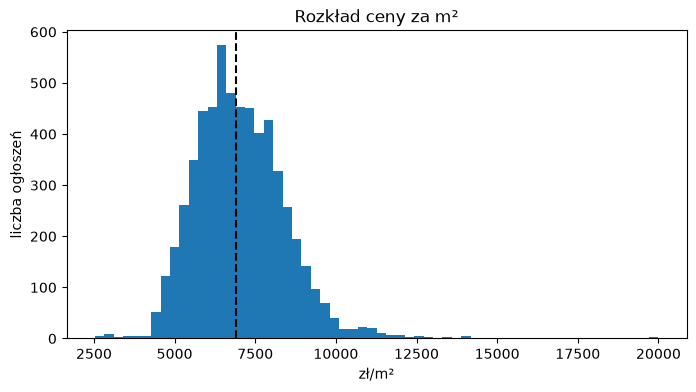

mediana: 6910.89


In [12]:
plt.figure(figsize=(8, 4))
plt.hist(data["price_per_m"], bins=60)
plt.axvline(data["price_per_m"].median(), color="black", linestyle="--")
plt.title("Rozkład ceny za m²")
plt.xlabel("zł/m²")
plt.ylabel("liczba ogłoszeń")
plt.show()

print("mediana:", data["price_per_m"].median())

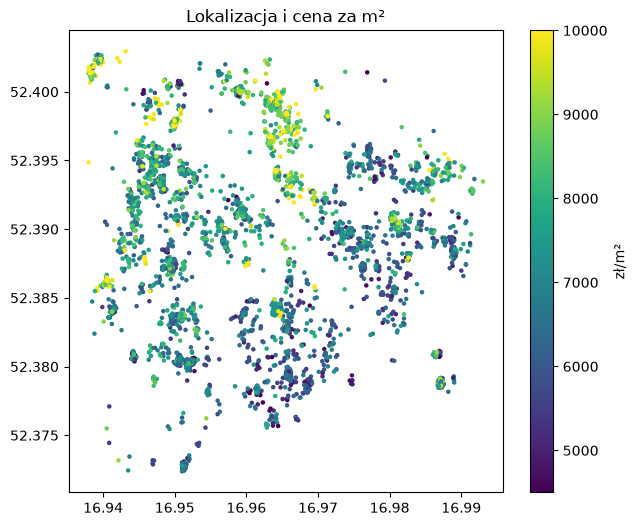

In [13]:
plt.figure(figsize=(7, 6))
plt.scatter(data["map_lon"], data["map_lat"], c=data["price_per_m"].clip(4500, 10000), s=5)
plt.colorbar(label="zł/m²")
plt.title("Lokalizacja i cena za m²")
plt.show()

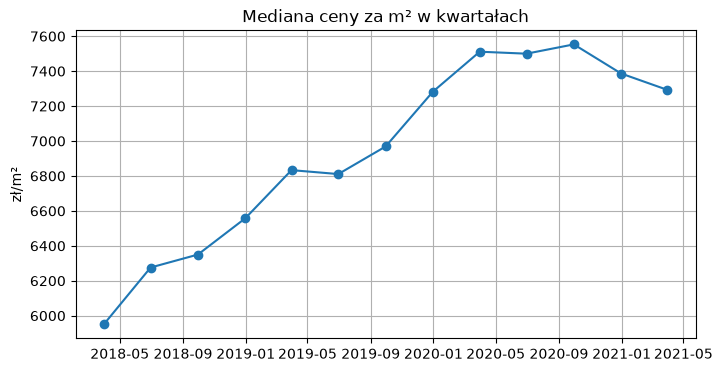

In [14]:
quarterly = data.set_index("created_at_first")["price_per_m"].resample("QE").median()

plt.figure(figsize=(8, 4))
plt.plot(quarterly.index, quarterly.values, marker="o")
plt.title("Mediana ceny za m² w kwartałach")
plt.ylabel("zł/m²")
plt.grid()
plt.show()

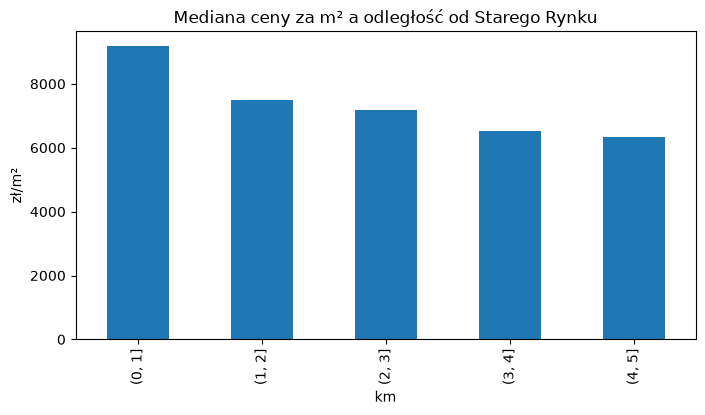

In [15]:
dist_bins = pd.cut(data["dist_center_km"], [0, 1, 2, 3, 4, 5, 15])
data.groupby(dist_bins, observed=True)["price_per_m"].median().plot.bar(figsize=(8, 4))
plt.title("Mediana ceny za m² a odległość od Starego Rynku")
plt.xlabel("km")
plt.ylabel("zł/m²")
plt.show()

In [16]:
cols = ["price_per_m", "m", "no_rooms", "dist_center_km", "build_year", "floor", "rent", "months_since_start"]
print("korelacja Spearmana z ceną za m²:")
print(data[cols].corr(method="spearman")["price_per_m"].round(2))

korelacja Spearmana z ceną za m²:
price_per_m           1.00
m                    -0.42
no_rooms             -0.41
dist_center_km       -0.33
build_year            0.42
floor                -0.15
rent                 -0.40
months_since_start    0.38
Name: price_per_m, dtype: float64


In [17]:
data.groupby("construction_status")["price_per_m"].agg(["median", "size"])

,median,size
construction_status,,
missing,6818.17,2266
ready_to_use,7151.64,3096
to_completion,6977.91,150
to_renovation,6049.18,423


## 6. Cechy z LLM

Z każdego opisu `gpt-4.1-mini` wyciągnął cechy w ustalonym formacie JSON: standard wykończenia,
stan techniczny, remont, umeblowanie, parking, taras, windę, rok budowy z opisu, osiedle itd.
Model miał nie szacować ceny. Poniżej prompt i funkcja, którą to zrobiliśmy (uruchomiona raz).

In [18]:
PROMPT = """Jesteś analitykiem rynku nieruchomości. Z ogłoszenia sprzedaży mieszkania (Poznań, rynek wtórny)
wyciągnij informacje WYŁĄCZNIE na podstawie treści. Jeśli czegoś nie ma w tekście, użyj "brak_info" lub null.
Nie podawaj i nie szacuj ceny. Oceny liczbowe dotyczą samego mieszkania (stan, standard, wyposażenie),
a nie lokalizacji ani ceny."""

YES_NO = {"type": ["boolean", "null"]}
SCHEMA = {
    "type": "object",
    "additionalProperties": False,
    "properties": {
        "finish_standard": {"type": "string", "enum": ["do_remontu", "do_odswiezenia", "dobry", "wysoki", "premium", "brak_info"]},
        "condition_score": {"type": ["integer", "null"], "description": "Stan techniczny 1 (ruina) - 5 (idealny / po generalnym remoncie)"},
        "attractiveness_score": {"type": "integer", "description": "Ogólna atrakcyjność mieszkania 1-10 (standard, wyposażenie, układ), bez lokalizacji i ceny"},
        "renovated_recently": YES_NO,
        "needs_investment": YES_NO,
        "furnished": {"type": "string", "enum": ["tak", "czesciowo", "nie", "brak_info"]},
        "kitchen": {"type": "string", "enum": ["oddzielna", "aneks", "brak_info"]},
        "building_kind": {"type": "string", "enum": ["kamienica", "blok_wielka_plyta", "blok", "apartamentowiec", "dom_lub_inne", "brak_info"]},
        "build_year_text": {"type": ["integer", "null"], "description": "Rok budowy budynku, jeśli podany lub jednoznaczny (np. 'lata 80' -> 1985)"},
        "parking": {"type": "string", "enum": ["garaz_podziemny", "garaz", "miejsce_postojowe", "parking_osiedlowy", "brak_info"]},
        "has_balcony": YES_NO,
        "has_terrace_or_garden": YES_NO,
        "has_storage_or_basement": YES_NO,
        "has_elevator": YES_NO,
        "air_conditioning_or_floor_heating": YES_NO,
        "gated_or_monitored": YES_NO,
        "quiet_green_area": YES_NO,
        "good_public_transport": YES_NO,
        "near_lake_or_park": YES_NO,
        "two_level_or_attic": YES_NO,
        "seller_type": {"type": "string", "enum": ["biuro_nieruchomosci", "osoba_prywatna", "brak_info"]},
        "no_commission": YES_NO,
        "neighborhood": {"type": ["string", "null"], "description": "Nazwa dzielnicy/osiedla w Poznaniu, np. 'Rataje', 'Jeżyce', 'Winogrady'"},
    },
}
SCHEMA["required"] = list(SCHEMA["properties"])


def ask_llm(client, text):
    response = client.chat.completions.create(
        model="gpt-4.1-mini",
        temperature=0,
        messages=[{"role": "system", "content": PROMPT}, {"role": "user", "content": text[:4000]}],
        response_format={"type": "json_schema",
                         "json_schema": {"name": "listing_features", "strict": True, "schema": SCHEMA}},
    )
    return json.loads(response.choices[0].message.content)

In [ ]:
# uruchomione raz dla wszystkich unikalnych opisów, wynik w cache/llm_features.jsonl
# (klucz API w zmiennej środowiskowej OPENAI_API_KEY):
# from openai import OpenAI
# client = OpenAI()
# with open("cache/llm_features.jsonl", "w", encoding="utf-8") as f:
#     for text in data["text"].unique():
#         key = hashlib.md5(text.encode("utf-8")).hexdigest()
#         f.write(json.dumps({"key": key, "features": ask_llm(client, text)}, ensure_ascii=False) + "\n")

Wczytanie zapisanych odpowiedzi. Kluczem jest hash tekstu, bo powtarzające się opisy wysyłaliśmy tylko raz.

In [19]:
llm = {}
with open("cache/llm_features.jsonl", encoding="utf-8") as f:
    for line in f:
        rec = json.loads(line)
        llm[rec["key"]] = rec["features"]

keys = data["text"].map(lambda t: hashlib.md5(t.encode("utf-8")).hexdigest())
L = pd.DataFrame([llm.get(k, {}) for k in keys]).add_prefix("llm_")
print("ogłoszeń bez cech LLM:", L["llm_finish_standard"].isna().sum())
L.head(3).T

ogłoszeń bez cech LLM: 0


,0,1,2
llm_finish_standard,brak_info,dobry,do_odswiezenia
llm_condition_score,NaN,4.0,3.0
llm_attractiveness_score,5,8,7
llm_renovated_recently,None,None,None
llm_needs_investment,None,False,True
llm_furnished,brak_info,tak,brak_info
llm_kitchen,oddzielna,aneks,oddzielna
llm_building_kind,blok,blok,blok
llm_build_year_text,NaN,NaN,1980.0
llm_parking,brak_info,brak_info,brak_info


Zamiana odpowiedzi na liczby.

In [20]:
L["llm_finish_standard"] = L["llm_finish_standard"].map(
    {"do_remontu": 1, "do_odswiezenia": 2, "dobry": 3, "wysoki": 4, "premium": 5})

# tak/nie -> 1/0
for col in L.columns:
    if L[col].isin([True, False, None]).all():
        L[col] = L[col].map({True: 1.0, False: 0.0})

L["llm_neighborhood"] = (L["llm_neighborhood"].fillna("brak").str.lower()
                         .str.replace(r"os\.|osiedle|poznań", "", regex=True)
                         .str.split(",").str[0].str.strip())

L["llm_build_year_text"] = pd.to_numeric(L["llm_build_year_text"], errors="coerce")
L.loc[~L["llm_build_year_text"].between(1850, 2022), "llm_build_year_text"] = np.nan

# rok budowy z params, a gdy go brak - z opisu
L["build_year_filled"] = data["build_year"].fillna(L["llm_build_year_text"])

In [21]:
data.groupby(L["llm_finish_standard"])["price_per_m"].agg(["median", "size"])

,median,size
llm_finish_standard,,
1.0,6320.75,478
2.0,6291.65,498
3.0,6714.29,3432
4.0,7964.29,1207
5.0,8131.58,105


## 7. Tabela cech

Cechy strukturalne + cechy z LLM w jednej tabeli `X`. Rzadkie kategorie (mniej niż 15 ogłoszeń w train)
łączymy w `other`, a kolumny tekstowe zamieniamy na typ `category`, który LightGBM obsługuje sam.

In [22]:
NUMERIC = ["m", "no_rooms", "map_lat", "map_lon", "district_lat", "district_lon", "floor",
           "building_floors_num", "build_year", "rent", "dist_center_km", "months_since_start",
           "m_per_room", "floor_ratio"]
struct_cols = NUMERIC + STRUCT_CAT + [c for c in data.columns if "__" in c]
llm_cols = list(L.columns)

X = pd.concat([data[struct_cols], L], axis=1)

for col in X.select_dtypes(exclude="number").columns:
    counts = X.loc[train.index, col].value_counts()
    X[col] = X[col].where(X[col].isin(counts[counts >= 15].index), "other")
    X[col] = pd.Categorical(X[col], categories=sorted(X.loc[train.index, col].unique()))

X_train = X.loc[train.index]
X_test = X.loc[test.index]
print("cechy strukturalne:", len(struct_cols), "| cechy z LLM:", len(llm_cols))

cechy strukturalne: 46 | cechy z LLM: 24


## 8. Cechy z tekstu

Tekst trafia do LightGBM jako **jedna liczba**: predykcja ceny z modelu Ridge na tekście.
Dla train jest to predykcja out-of-fold (5-krotna walidacja po grupach duplikatów), żeby nie było wycieku.

In [23]:
cv = GroupKFold(n_splits=5)


def text_feature(Z_train, Z_test, alpha):
    ridge = Ridge(alpha=alpha)
    oof = cross_val_predict(ridge, Z_train, y_train, cv=cv, groups=train["group"])
    ridge.fit(Z_train, y_train)
    return oof, ridge.predict(Z_test)

### TF-IDF

In [24]:
text_train = train["text"].map(strip_numbers).str.lower()
text_test = test["text"].map(strip_numbers).str.lower()

tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), min_df=3, sublinear_tf=True)
T_train = tfidf.fit_transform(text_train)
T_test = tfidf.transform(text_test)
print(T_train.shape)

X_train["txt_tfidf"], X_test["txt_tfidf"] = text_feature(T_train, T_test, alpha=3)

(4747, 50000)


Druga wersja: TF-IDF zredukowany przez SVD do 50 składowych, doklejonych bezpośrednio jako cechy.

In [25]:
svd = TruncatedSVD(n_components=50, random_state=42)
svd_cols = [f"svd_{i}" for i in range(50)]
X_train[svd_cols] = svd.fit_transform(T_train)
X_test[svd_cols] = svd.transform(T_test)

### Embeddingi

- Sentence-BERT `paraphrase-multilingual-MiniLM-L12-v2` (liczony lokalnie),
- OpenAI `text-embedding-3-small`.

Oba policzone raz na tekście bez liczb i zapisane w `cache/`.

In [26]:
# tak były policzone embeddingi Sentence-BERT:
# from sentence_transformers import SentenceTransformer
# sbert = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
# sbert.max_seq_length = 256
# emb = sbert.encode(list(data["text"].map(strip_numbers)), normalize_embeddings=True)

# tak były policzone embeddingi OpenAI (klucz API w zmiennej środowiskowej OPENAI_API_KEY):
# from openai import OpenAI
# client = OpenAI()
# texts = list(data["text"].map(strip_numbers))
# emb = []
# for i in range(0, len(texts), 100):
#     batch = [t[:12000] or " " for t in texts[i:i + 100]]
#     response = client.embeddings.create(model="text-embedding-3-small", input=batch)
#     emb += [d.embedding for d in response.data]
# np.save("cache/emb_openai.npy", np.array(emb, dtype=np.float32))

emb_sbert = np.load("cache/emb_sbert.npy")
emb_openai = np.load("cache/emb_openai.npy")
print(emb_sbert.shape, emb_openai.shape)

X_train["txt_sbert"], X_test["txt_sbert"] = text_feature(emb_sbert[train.index], emb_sbert[test.index], alpha=1)
X_train["txt_openai"], X_test["txt_openai"] = text_feature(emb_openai[train.index], emb_openai[test.index], alpha=1)

(5935, 384) (5935, 1536)


## 9. Modele

Główny model to LightGBM z tymi samymi parametrami, zmienia się tylko zestaw cech.
Dla porównania liczymy też Ridge na samym tekście (bez cech strukturalnych).

In [27]:
results = []


def evaluate(nr, model, features, pred):
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    results.append({
        "nr": nr,
        "model": model,
        "cechy": features,
        "RMSE": rmse,
        "MAE": mean_absolute_error(y_test, pred),
        "MAPE_%": np.mean(np.abs(y_test - pred) / y_test) * 100,
        "R2": r2_score(y_test, pred),
    })
    print(f"{nr}. {model} | {features}: RMSE = {rmse:.1f}")


def make_lgbm():
    return lgb.LGBMRegressor(n_estimators=800, learning_rate=0.03, num_leaves=31, subsample=0.8,
                             subsample_freq=1, colsample_bytree=0.7, random_state=42, verbose=-1)


def fit_lgbm(cols):
    model = make_lgbm().fit(X_train[cols], y_train)
    return model.predict(X_test[cols])

In [28]:
evaluate("0", "mediana z train", "brak", np.full(len(y_test), np.median(y_train)))
evaluate("1", "LightGBM", "strukturalne (baseline)", fit_lgbm(struct_cols))

0. mediana z train | brak: RMSE = 1376.8
1. LightGBM | strukturalne (baseline): RMSE = 617.8


In [29]:
evaluate("2a", "Ridge", "tylko tekst: TF-IDF", X_test["txt_tfidf"])
evaluate("2b", "LightGBM", "strukturalne + TF-IDF (predykcja Ridge)", fit_lgbm(struct_cols + ["txt_tfidf"]))
evaluate("2c", "LightGBM", "strukturalne + TF-IDF -> SVD (50 kolumn)", fit_lgbm(struct_cols + svd_cols))

2a. Ridge | tylko tekst: TF-IDF: RMSE = 849.2
2b. LightGBM | strukturalne + TF-IDF (predykcja Ridge): RMSE = 564.6
2c. LightGBM | strukturalne + TF-IDF -> SVD (50 kolumn): RMSE = 570.3


In [30]:
evaluate("3a", "Ridge", "tylko tekst: embeddingi SBERT", X_test["txt_sbert"])
evaluate("3b", "LightGBM", "strukturalne + embeddingi SBERT (predykcja Ridge)", fit_lgbm(struct_cols + ["txt_sbert"]))
evaluate("3c", "Ridge", "tylko tekst: embeddingi OpenAI", X_test["txt_openai"])
evaluate("3d", "LightGBM", "strukturalne + embeddingi OpenAI (predykcja Ridge)", fit_lgbm(struct_cols + ["txt_openai"]))

3a. Ridge | tylko tekst: embeddingi SBERT: RMSE = 1157.5
3b. LightGBM | strukturalne + embeddingi SBERT (predykcja Ridge): RMSE = 601.1
3c. Ridge | tylko tekst: embeddingi OpenAI: RMSE = 961.8
3d. LightGBM | strukturalne + embeddingi OpenAI (predykcja Ridge): RMSE = 586.5


In [31]:
evaluate("4", "LightGBM", "strukturalne + cechy z LLM", fit_lgbm(struct_cols + llm_cols))

4. LightGBM | strukturalne + cechy z LLM: RMSE = 564.0


In [32]:
all_cols = struct_cols + llm_cols + ["txt_tfidf", "txt_sbert", "txt_openai"]
evaluate("5", "LightGBM", "wszystko: strukturalne + LLM + TF-IDF + SBERT + OpenAI", fit_lgbm(all_cols))

5. LightGBM | wszystko: strukturalne + LLM + TF-IDF + SBERT + OpenAI: RMSE = 549.0


## 10. LLM wycenia mieszkanie sam

Dla porównania `gpt-4.1-mini` dostał dane mieszkania i opis (bez liczb) i sam podawał cenę za m²:
- **zero-shot**: tylko własna wiedza modelu,
- **knn**: dodatkowo 10 najbliższych geograficznie ogłoszeń z train razem z ich cenami.

Odpowiedzi są zapisane w `results/llm_direct_*.csv`.

In [ ]:
# tak LLM wyceniał mieszkania ze zbioru testowego (uruchomione raz,
# klucz API w zmiennej środowiskowej OPENAI_API_KEY):
# from openai import OpenAI
# from sklearn.neighbors import NearestNeighbors
#
# PRICE_PROMPT = """Jesteś rzeczoznawcą majątkowym w Poznaniu. Oszacuj cenę ofertową za metr kwadratowy (PLN/m2)
# mieszkania z rynku wtórnego w momencie publikacji ogłoszenia. Odpowiedz wyłącznie JSON-em: {"price_per_m": liczba}."""
#
#
# def make_prompt(row, neighbors=None):
#     text = (f"Data ogłoszenia: {row.created_at_first:%Y-%m}\n"
#             f"Metraż: {row.m} m2, pokoje: {row.no_rooms}, piętro: {row.floor} z {row.building_floors_num}\n"
#             f"Rok budowy: {row.build_year}, typ budynku: {row.building_type}, stan: {row.construction_status}\n"
#             f"Odległość od Starego Rynku: {row.dist_center_km:.1f} km "
#             f"(współrzędne {row.map_lat:.4f}, {row.map_lon:.4f})\n\n"
#             f"Opis (liczby usunięte):\n{strip_numbers(row.text)[:2500]}")
#     if neighbors is not None:
#         text += "\n\nPodobne pobliskie ogłoszenia z ceną za m2:"
#         for n in neighbors.itertuples():
#             text += (f"\n- {n.created_at_first:%Y-%m}, {n.m} m2, {n.no_rooms} pok., rok bud. {n.build_year}, "
#                      f"{n.dist_center_km:.1f} km od centrum: {n.price_per_m:.0f} zł/m2")
#     return text
#
#
# def ask_price(client, prompt):
#     response = client.chat.completions.create(
#         model="gpt-4.1-mini", temperature=0, response_format={"type": "json_object"},
#         messages=[{"role": "system", "content": PRICE_PROMPT}, {"role": "user", "content": prompt}])
#     return float(json.loads(response.choices[0].message.content)["price_per_m"])
#
#
# # 10 najbliższych geograficznie ogłoszeń z train (współrzędne przeliczone mniej więcej na km)
# coords_train = np.c_[train["map_lat"] * 111, train["map_lon"] * 68]
# coords_test = np.c_[test["map_lat"] * 111, test["map_lon"] * 68]
# _, neighbors = NearestNeighbors(n_neighbors=10).fit(coords_train).kneighbors(coords_test)
#
# client = OpenAI()
# for variant in ["zero_shot", "knn"]:
#     preds = []
#     for i, row in enumerate(test.itertuples()):
#         context = train.iloc[neighbors[i]] if variant == "knn" else None
#         preds.append(ask_price(client, make_prompt(row, context)))
#     pd.DataFrame({"id": test["id"], "pred": preds}).to_csv(f"results/llm_direct_{variant}.csv", index=False)

In [33]:
pred = pd.read_csv("results/llm_direct_knn.csv").set_index("id")["pred"]
evaluate("6a", "gpt-4.1-mini", "dane mieszkania + opis + 10 sąsiadów z ceną", pred.reindex(test["id"]).values)

pred = pd.read_csv("results/llm_direct_zero_shot.csv").set_index("id")["pred"]
evaluate("6b", "gpt-4.1-mini", "dane mieszkania + opis (zero-shot)", pred.reindex(test["id"]).values)

6a. gpt-4.1-mini | dane mieszkania + opis + 10 sąsiadów z ceną: RMSE = 963.0
6b. gpt-4.1-mini | dane mieszkania + opis (zero-shot): RMSE = 1867.0


## 11. Wyniki

In [34]:
results = pd.DataFrame(results).round(2)
results.to_csv("results/results.csv", index=False)
results

,nr,model,cechy,RMSE,MAE,MAPE_%,R2
0,0,mediana z train,brak,1376.76,1088.19,15.92,-0.01
1,1,LightGBM,strukturalne (baseline),617.81,433.89,6.27,0.80
2,2a,Ridge,tylko tekst: TF-IDF,849.22,636.34,9.58,0.62
3,2b,LightGBM,strukturalne + TF-IDF (predykcja Ridge),564.60,391.05,5.66,0.83
4,2c,LightGBM,strukturalne + TF-IDF -> SVD (50 kolumn),570.30,386.65,5.61,0.83
5,3a,Ridge,tylko tekst: embeddingi SBERT,1157.54,909.69,13.61,0.29
6,3b,LightGBM,strukturalne + embeddingi SBERT (predykcja Ridge),601.14,425.96,6.14,0.81
7,3c,Ridge,tylko tekst: embeddingi OpenAI,961.80,747.19,11.19,0.51
8,3d,LightGBM,strukturalne + embeddingi OpenAI (predykcja Ri...,586.48,413.48,5.99,0.82
9,4,LightGBM,strukturalne + cechy z LLM,564.03,388.48,5.57,0.83


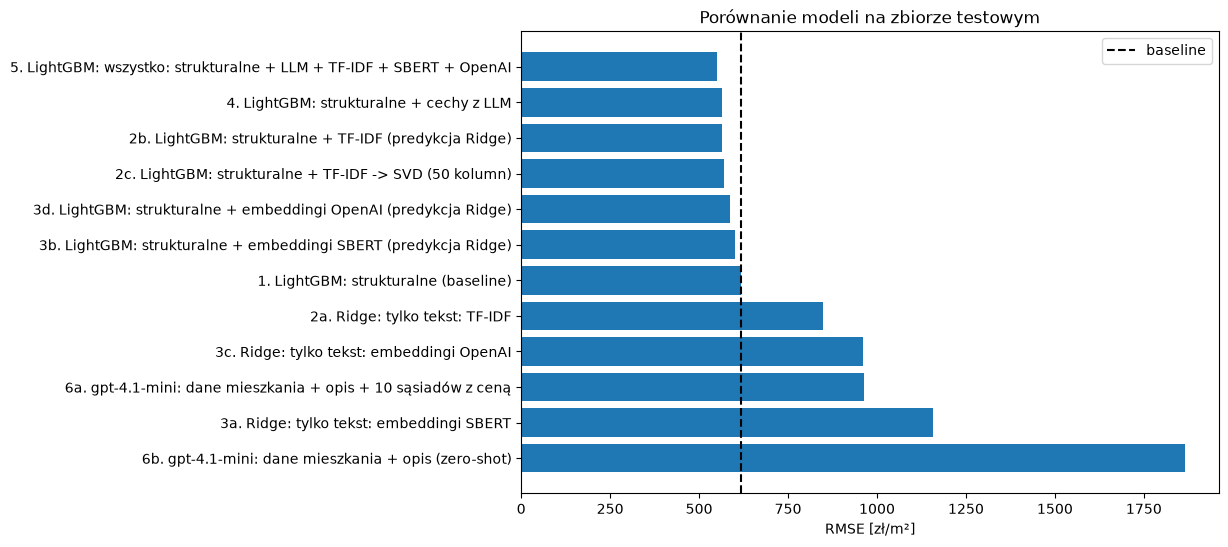

In [35]:
plot = results[results["nr"] != "0"].sort_values("RMSE", ascending=False)
labels = plot["nr"] + ". " + plot["model"] + ": " + plot["cechy"]

plt.figure(figsize=(9, 6))
plt.barh(labels, plot["RMSE"])
plt.axvline(results.loc[1, "RMSE"], color="black", linestyle="--", label="baseline")
plt.xlabel("RMSE [zł/m²]")
plt.title("Porównanie modeli na zbiorze testowym")
plt.legend()
plt.show()

Które cechy najbardziej pomagają w pełnym modelu (udział w zysku z podziałów drzew):

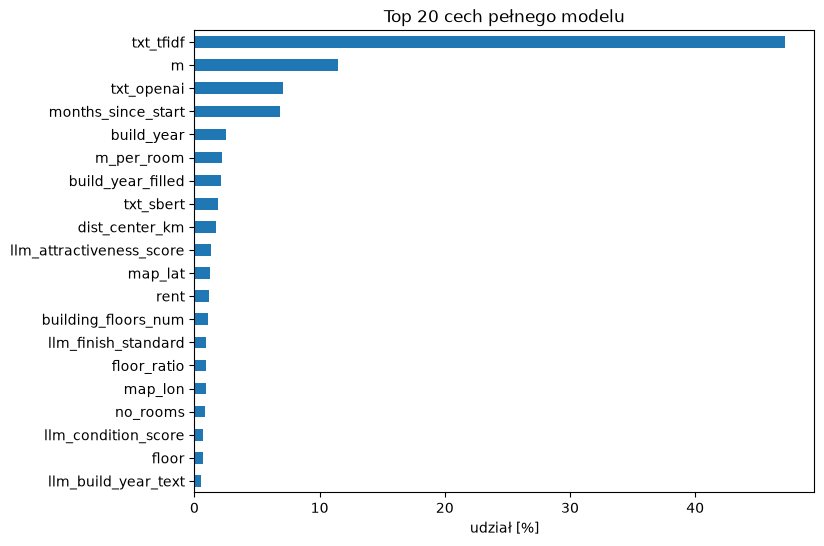

In [36]:
full_model = make_lgbm().fit(X_train[all_cols], y_train)
importance = pd.Series(full_model.booster_.feature_importance("gain"), index=all_cols)
importance = importance / importance.sum() * 100

importance.sort_values().tail(20).plot.barh(figsize=(8, 6))
plt.xlabel("udział [%]")
plt.title("Top 20 cech pełnego modelu")
plt.show()

## 12. Porównanie algorytmów

Czy wybór LightGBM ma znaczenie? Kilka algorytmów na dwóch zestawach cech: same cechy strukturalne
i wszystkie cechy. Bez strojenia hiperparametrów.
Ridge i Random Forest nie obsługują kategorii ani braków, więc dostają one-hot i braki uzupełnione medianą.

In [37]:
algorithms = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "Random Forest": RandomForestRegressor(n_estimators=500, min_samples_leaf=2, max_features=0.5,
                                           n_jobs=-1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=800, learning_rate=0.03,
                                                          categorical_features="from_dtype", random_state=42),
    "XGBoost": XGBRegressor(n_estimators=800, learning_rate=0.03, max_depth=6, subsample=0.8,
                            colsample_bytree=0.7, enable_categorical=True, random_state=42),
    "LightGBM": make_lgbm(),
}

algo_results = []
for name, model in algorithms.items():
    row = {"algorytm": name}
    for label, cols in [("struktura", struct_cols), ("wszystko", all_cols)]:
        A_train, A_test = X_train[cols], X_test[cols]
        if name in ["Ridge", "Random Forest"]:
            A_train = pd.get_dummies(A_train, dtype=float)
            A_test = pd.get_dummies(A_test, dtype=float)
            A_train, A_test = A_train.fillna(A_train.median()), A_test.fillna(A_train.median())
        pred = model.fit(A_train, y_train).predict(A_test)
        row[f"RMSE {label}"] = np.sqrt(mean_squared_error(y_test, pred))
    algo_results.append(row)
    print(row)

algo_results = pd.DataFrame(algo_results).round(1)
algo_results.to_csv("results/algorithms.csv", index=False)
algo_results

{'algorytm': 'Ridge', 'RMSE struktura': np.float64(875.8280346814829), 'RMSE wszystko': np.float64(689.7345898313538)}
{'algorytm': 'Random Forest', 'RMSE struktura': np.float64(642.3938309824576), 'RMSE wszystko': np.float64(597.7033909786248)}
{'algorytm': 'HistGradientBoosting', 'RMSE struktura': np.float64(619.9426721823487), 'RMSE wszystko': np.float64(554.6273989198684)}
{'algorytm': 'XGBoost', 'RMSE struktura': np.float64(610.7220882756075), 'RMSE wszystko': np.float64(552.1908038702675)}
{'algorytm': 'LightGBM', 'RMSE struktura': np.float64(617.8058289924975), 'RMSE wszystko': np.float64(549.0059220885414)}


,algorytm,RMSE struktura,RMSE wszystko
0,Ridge,875.8,689.7
1,Random Forest,642.4,597.7
2,HistGradientBoosting,619.9,554.6
3,XGBoost,610.7,552.2
4,LightGBM,617.8,549.0


## 13. Strojenie XGBoost

Losowo sprawdzamy 30 kombinacji hiperparametrów. Każdą oceniamy 5-krotną walidacją krzyżową **tylko na train**
(po grupach duplikatów), a test zostaje do końcowego porównania. Stroimy osobno dla cech strukturalnych
i dla wszystkich cech.

In [38]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "n_estimators": [300, 600, 1000, 1500],
    "learning_rate": [0.01, 0.02, 0.03, 0.05, 0.1],
    "max_depth": [3, 4, 5, 6, 8],
    "min_child_weight": [1, 3, 5, 10],
    "subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.4, 0.5, 0.6, 0.7, 0.8, 1.0],
    "reg_lambda": [0.1, 1, 5, 10],
}

In [39]:
tuning_results = []
for label, cols in [("struktura", struct_cols), ("wszystko", all_cols)]:
    search = RandomizedSearchCV(
        XGBRegressor(enable_categorical=True, random_state=42),
        param_grid, n_iter=30, cv=cv, scoring="neg_root_mean_squared_error", random_state=42,
    )
    search.fit(X_train[cols], y_train, groups=train["group"])
    pred = search.best_estimator_.predict(X_test[cols])

    print(label, search.best_params_)
    tuning_results.append({
        "cechy": label,
        "RMSE walidacja (CV)": -search.best_score_,
        "RMSE test przed strojeniem": algo_results.loc[algo_results["algorytm"] == "XGBoost", f"RMSE {label}"].item(),
        "RMSE test po strojeniu": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE test po strojeniu": mean_absolute_error(y_test, pred),
    })

tuning_results = pd.DataFrame(tuning_results).round(1)
tuning_results.to_csv("results/xgboost_tuning.csv", index=False)
tuning_results

struktura {'subsample': 0.8, 'reg_lambda': 0.1, 'n_estimators': 1500, 'min_child_weight': 1, 'max_depth': 8, 'learning_rate': 0.02, 'colsample_bytree': 0.6}
wszystko {'subsample': 0.8, 'reg_lambda': 0.1, 'n_estimators': 1000, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.6}


,cechy,RMSE walidacja (CV),RMSE test przed strojeniem,RMSE test po strojeniu,MAE test po strojeniu
0,struktura,694.8,610.7,595.0,408.2
1,wszystko,630.0,552.2,547.1,369.6


## 14. Wnioski

- **Tekst poprawia predykcję.** Najlepszy model (struktura + LLM + TF-IDF + embeddingi) ma RMSE 549 zł/m²,
  baseline 618 (−11,1%). MAE spada z 434 do 378 zł/m².
- **Pojedynczo najlepiej działają cechy z LLM (564) i TF-IDF (565).** Prosty TF-IDF nie ustępuje embeddingom.
  Embeddingi OpenAI (586) są lepsze od Sentence-BERT (601).
- **LLM dobrze rozpoznaje standard wykończenia:** mediana ok. 6 300 zł/m² dla „do remontu”
  i ok. 8 000 zł/m² dla „wysokiego”. Uzupełnia też rok budowy, którego brakuje w połowie ogłoszeń.
- **LLM wyceniający sam przegrywa z modelem:** zero-shot RMSE 1867 (gorzej niż mediana), z 10 sąsiadami 963.
  LLM lepiej używać do wyciągania cech, a wycenę zostawić modelowi uczonemu na danych.
- **Algorytm ma mniejsze znaczenie niż cechy:** LightGBM, XGBoost i HistGradientBoosting są blisko siebie
  (549–555), Random Forest 598, Ridge 690. Tekst poprawia każdy z nich.
- **Strojenie XGBoost daje niewielki zysk:** na cechach strukturalnych RMSE spada z 611 do 595,
  na wszystkich cechach z 552 do 547 (najlepszy wynik w projekcie). Po strojeniu tekst nadal poprawia
  wynik o ok. 8% (595 → 547), więc poprawa nie wynika ze słabo ustawionego baseline'u.
- **Ograniczenia:** jedno miasto, lata 2018–2021 z silnym wzrostem cen, ceny ofertowe a nie transakcyjne.